In [1]:
import sys; sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from clv import config as C
from clv.storage import load_raw_tables
from clv.metrics import monthly_churn, format_usd
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.figsize"] = (9, 3.6)
T = load_raw_tables()
cu, sub, rv, us, tk, ev, mk = (T[k] for k in ["customers","subscriptions","revenue_monthly","usage_monthly","support_tickets","billing_events","marketing_channels"])
pd.DataFrame({"rows": {k: len(v) for k, v in T.items()}})

,rows
customers,5000
subscriptions,5094
usage_monthly,77565
support_tickets,18715
revenue_monthly,77676
marketing_channels,150
billing_events,9672


# 1. Data Overview


In [2]:
print("Customers by size band:", cu.company_size.value_counts(normalize=True).round(3).to_dict())
print("Annual billing share of subscriptions:", round((sub.billing_cycle == "Annual").mean(), 3))
print("Events:", ev.event_type.value_counts().to_dict())

Customers by size band: {'50-249': 0.438, '1-49': 0.358, '250-999': 0.172, '1000+': 0.032}
Annual billing share of subscriptions: 0.31
Events: {'new_subscription': 5000, 'payment_failure': 2218, 'cancellation': 1691, 'upgrade': 380, 'downgrade': 289, 'reactivation': 94}


# 2. Revenue growth and concentration

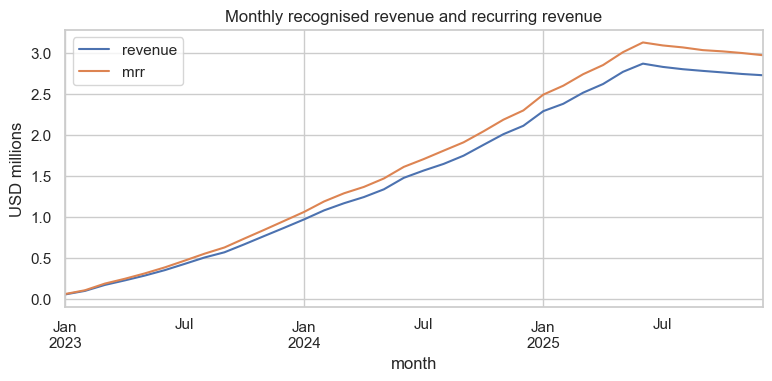

Total revenue: $55.43M | first month: $59.4K | last month: $2.73M
Top 10% of customers: 0.51 | top 20%: 0.7


In [4]:
m = rv.groupby("month").agg(revenue=("recognized_revenue","sum"), mrr=("recurring_revenue","sum"))
ax = (m / 1e6).plot(); ax.set_ylabel("USD millions"); ax.set_title("Monthly recognised revenue and recurring revenue"); plt.show()
tot = rv.groupby("customer_id").recognized_revenue.sum().sort_values(ascending=False)
print("Total revenue:", format_usd(tot.sum()), "| first month:", format_usd(m.revenue.iloc[0]), "| last month:", format_usd(m.revenue.iloc[-1]))
print("Top 10% of customers:", round(tot.head(int(len(tot)*.1)).sum()/tot.sum(), 3), "| top 20%:", round(tot.head(int(len(tot)*.2)).sum()/tot.sum(), 3))

# 3. Churn Drivers

Customers: 3,612 | overall 12-month cancellation: 28.1%


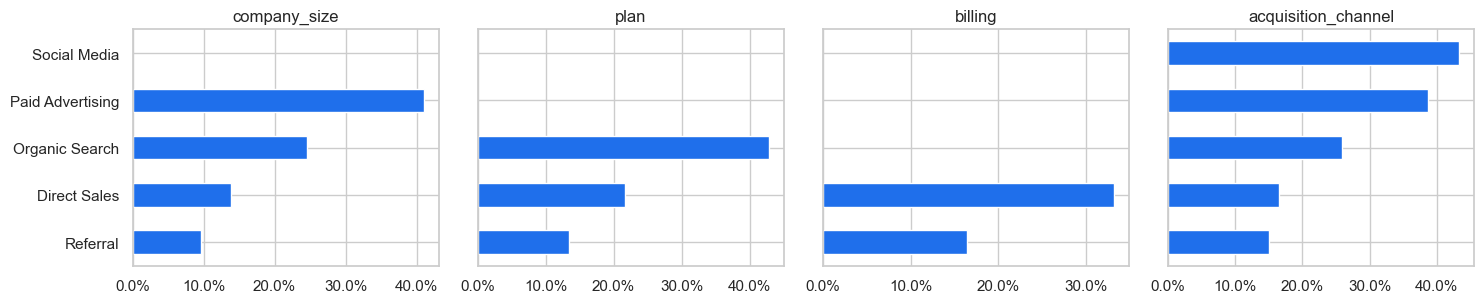

In [5]:
first_plan = ev[ev.event_type == "new_subscription"].set_index("customer_id").plan_after
first_bill = sub.sort_values("subscription_start_date").groupby("customer_id").billing_cycle.first()
cancel = ev[ev.event_type == "cancellation"].groupby("customer_id").event_date.min()
d = cu.assign(plan=cu.customer_id.map(first_plan), billing=cu.customer_id.map(first_bill), cancel=cu.customer_id.map(cancel))
d = d[d.signup_date <= "2024-12-31"].copy()
d["cancelled_12m"] = (d.cancel - d.signup_date).dt.days <= 365
print(f"Customers: {len(d):,} | overall 12-month cancellation: {d.cancelled_12m.mean():.1%}")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, col in zip(axes, ["company_size", "plan", "billing", "acquisition_channel"]):
    r = d.groupby(col).cancelled_12m.mean().sort_values(); r.plot.barh(ax=ax, color="#1f6feb"); ax.set_title(col); ax.set_ylabel("")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()

# 4. Leading indicators and a bias trap 


In [8]:
# engagement in the the first 3 months vs churn afterwards
u3 = us.merge(cu[["customer_id","signup_date"]], on="customer_id")
u3 = u3[u3.observation_month <= u3.signup_date + pd.DateOffset(months=3)]
d["early_active_days"] = d.customer_id.map(u3.groupby("customer_id").active_days.mean())
e = d.dropna(subset=["early_active_days"])
e = e[e.cancel.isna() | (e.cancel > e.signup_date + pd.DateOffset(months=3))].copy()
e["quartile"] = pd.qcut(e.early_active_days, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
print(e.groupby("quartile").cancelled_12m.mean().round(3).to_dict())

{'Q1 low': 0.444, 'Q2': 0.284, 'Q3': 0.178, 'Q4 high': 0.103}


In [9]:
# naive payment-failure comparison (lifetime count)-> biased by exposure time
pf = ev[ev.event_type == "payment_failure"].customer_id.value_counts()
d["had_failure"] = d.customer_id.map(pf).fillna(0) > 0
print("Naive: cancelled_12m by 'ever had a payment failure':", d.groupby("had_failure").cancelled_12m.mean().round(3).to_dict())

Naive: cancelled_12m by 'ever had a payment failure': {False: 0.308, True: 0.232}


# 5. Support

In [10]:
print(f"Tickets per customer-month: {len(tk)/len(us):.2f} | unresolved: {tk.resolution_time_hours.isna().mean():.1%} | CSAT missing: {tk.customer_satisfaction_score.isna().mean():.0%}")
print(tk.groupby("priority").agg(median_hours=("resolution_time_hours","median"), csat=("customer_satisfaction_score","mean")).round(2).loc[["Low","Medium","High","Critical"]])

Tickets per customer-month: 0.24 | unresolved: 4.1% | CSAT missing: 38%
          median_hours  csat
priority                    
Low               39.0  3.41
Medium            21.2  3.71
High               8.1  3.98
Critical           3.4  4.16


# 6. Acquisition channels

In [11]:
g = cu.merge(rv.groupby("customer_id").recognized_revenue.sum().rename("revenue"), on="customer_id", how="left").fillna({"revenue": 0})
ch = g.groupby("acquisition_channel").agg(customers=("revenue","size"), avg_cac=("acquisition_cost","mean"), avg_revenue_to_date=("revenue","mean"))
ch["revenue_to_cac"] = ch.avg_revenue_to_date / ch.avg_cac
ch.round(1).sort_values("revenue_to_cac", ascending=False)

,customers,avg_cac,avg_revenue_to_date,revenue_to_cac
acquisition_channel,,,,
Organic Search,1217,192.1,8635.5,44.9
Referral,793,376.9,12249.8,32.5
Social Media,797,484.9,5009.5,10.3
Paid Advertising,1216,871.7,8399.3,9.6
Direct Sales,977,4226.2,21496.5,5.1


# 7. Seasonality and data quality

Pooled monthly logo churn: 2.33%


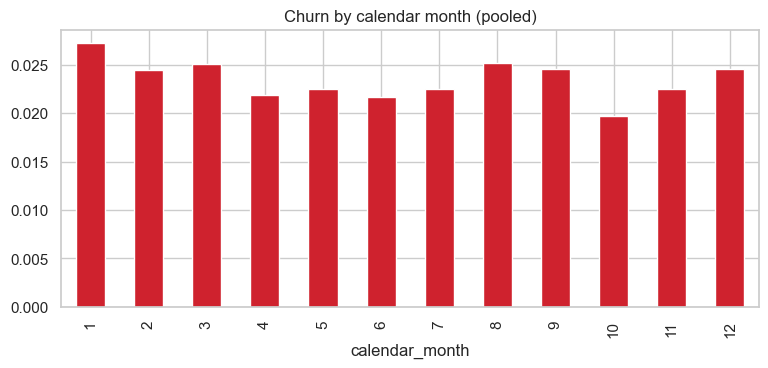

customers        employee_count                  1.4
                 acquisition_cost                1.5
subscriptions    subscription_end_date          66.8
usage_monthly    monthly_logins                  1.5
                 features_used                   2.5
                 feature_adoption_rate           2.5
                 session_duration_minutes        2.9
                 usage_change_percentage         7.9
support_tickets  resolution_time_hours           4.1
                 customer_satisfaction_score    37.6
billing_events   plan_before                    52.7
                 plan_after                     17.5
dtype: float64


In [12]:
mc = monthly_churn(rv, ev); mc["calendar_month"] = mc.month.dt.month
by_m = mc.groupby("calendar_month").apply(lambda x: x.cancellations.sum() / x.active_at_start.sum())
print(f"Pooled monthly logo churn: {mc.cancellations.sum()/mc.active_at_start.sum():.2%}")
by_m.plot.bar(color="#cf222e"); plt.title("Churn by calendar month (pooled)"); plt.show()
print((pd.concat({k: v.isna().mean() for k, v in T.items()}).loc[lambda s: s > 0] * 100).round(1))

# 8. What the model learned(backtest snapshot 2024-12-31)


              predicted_12m   actual_12m  error
segment                                        
High Value     1.524348e+07  15386533.80 -0.009
Low Value      8.553231e+05    870021.06 -0.017
Medium Value   6.355623e+06   6471416.47 -0.018
Portfolio error - model: -0.012 | trailing run-rate x12: 0.039 | MRR x12: 0.143


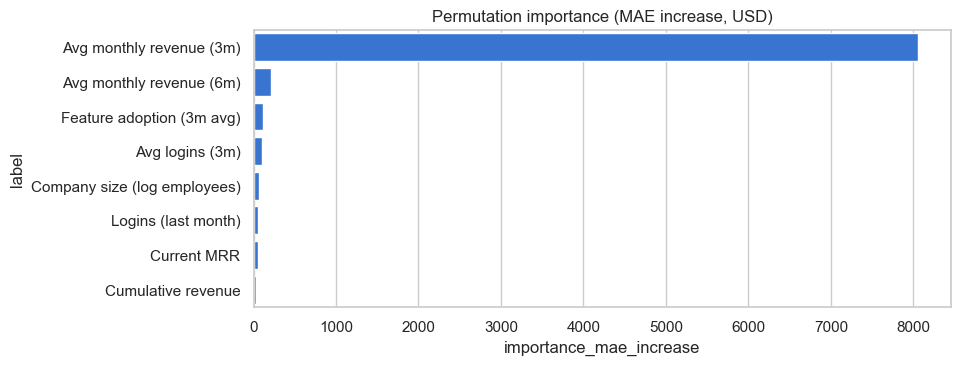

In [13]:
s = pd.read_csv("../data/processed/customer_snapshots.csv", parse_dates=["snapshot_date"]); b = s[s.split == "backtest"]
seg = b.groupby("segment")[["predicted_12m","actual_12m"]].sum(); seg["error"] = seg.predicted_12m / seg.actual_12m - 1
print(seg.round(3))
print("Portfolio error - model:", round(b.predicted_12m.sum()/b.actual_12m.sum()-1, 3),
      "| trailing run-rate x12:", round((b.rev_3m_avg*12).sum()/b.actual_12m.sum()-1, 3),
      "| MRR x12:", round((b.mrr_now*12).sum()/b.actual_12m.sum()-1, 3))
pi = pd.read_csv("../data/processed/permutation_importance.csv").head(8)
sns.barplot(data=pi, y="label", x="importance_mae_increase", color="#1f6feb"); plt.title("Permutation importance (MAE increase, USD)"); plt.show()